# Reproducing ResNet / ResNet-tiny on ESC-50
**Paper:** Goulão, Bandeira, Martins, Oliveira
— *Training environmental sound classification models for real-world deployment in edge devices*, Discover Applied Sciences (2024) 6:166.

**Target (Table 3, ESC-50, 5-fold CV accuracy):** ResNet **81.9 %**, ResNet-tiny **81.6 %**.
| | ResNet | ResNet-tiny |
|---|---|---|
| Backbone | YOLOv4-CSP (CSP-Darknet, layers 0-10 / darknet layers 0-98) | YOLOv7-tiny (layers 0-28) |
| Init | COCO-pretrained | COCO-pretrained |
| Backbone output channels | 1024 | 512 |
| Params (paper, Table 2) | 26,610,535 | 2,996,903 |
**Shared head:** `AdaptiveAvgPool(1x1) → Flatten → Linear(C,1024) → Hardswish → Dropout(0.2) → Linear(1024, n_classes)`
**Input:** 10 s @ 22.05 kHz → three 128-band log-mel spectrograms (win/hop = 551/220, 1102/551, 2205/1102) stacked as 3 channels → time axis resized to 250 → `(3,128,250)`.
**Training (Sect. 8):** 5 folds × 500 epochs, batch 64, Adam (wd 1e-3), cross-entropy, lr 1e-4 ×0.1 at every third of training, augmentations = rolling + frequency masking + time masking + mixup (λ=0.2).

### Runtime
Paper (V100S, different task): 11.5 h ResNet / 4.5 h ResNet-tiny for 2 folds × 300 epochs on ~6.5 k clips per fold.

Scaling by number of samples processed, ESC-50 (5 × 500 epochs × 1600 clips) is roughly **12 h + 5 h** on a V100S-class GPU.

## 1. Configuration
#
**Lokasi penyimpanan (semua di dalam folder project):**
```
<PROJECT_DIR>/
├── esc50_repro/            # repo YOLO, bobot COCO, dataset ESC-50, cache spektrogram
├── outputs/                
│   ├── experiment_log.json
│   ├── results/            # {model}_fold{k}.json, {model}_fold{k}_history.csv, {model}_fold{k}.pt
│   ├── results_smoke/      # hasil smoke test
│   ├── checkpoints/        # checkpoint sementara untuk resume (dihapus saat fold selesai)
│   ├── figures/            # accuracy_curves.png
│   ├── summary_results.csv / per_fold_results.csv
│   └── logs/run_log.txt
```

In [ ]:
import os
import sys
import json
import math
import time
import copy
import random
import hashlib
import subprocess
import contextlib
import platform
import urllib.request
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchaudio
import soundfile as sf
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

# ------------------------------------------------------------------
# PROJECT DIRECTORY
# ------------------------------------------------------------------
def find_project_dir():
    env = os.environ.get("PROJECT_DIR")
    if env:
        return Path(env).expanduser().resolve()
    if Path("/kaggle/working").exists():
        return Path("/kaggle/working")
    return Path.cwd().resolve()

PROJECT_DIR = find_project_dir()
WORK        = PROJECT_DIR / "esc50_repro"               # repos, weights, dataset, cache
OUT_DIR     = PROJECT_DIR / "outputs"                   # HASIL
RESULTS_DIR = OUT_DIR / "results"
SMOKE_DIR   = OUT_DIR / "results_smoke"
CKPT_DIR    = OUT_DIR / "checkpoints"
FIG_DIR     = OUT_DIR / "figures"
LOG_DIR     = OUT_DIR / "logs"
for _d in (WORK, RESULTS_DIR, SMOKE_DIR, CKPT_DIR, FIG_DIR, LOG_DIR):
    _d.mkdir(parents=True, exist_ok=True)


# ---- helper penyimpanan ----
def durable_write(path, data, mode="w"):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    with open(tmp, mode) as f:
        f.write(data); f.flush(); os.fsync(f.fileno())
    os.replace(tmp, path)
    assert path.exists() and path.stat().st_size > 0, f"GAGAL menyimpan: {path}"
    return path

def durable_torch_save(obj, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    with open(tmp, "wb") as f:
        torch.save(obj, f); f.flush(); os.fsync(f.fileno())
    os.replace(tmp, path)
    assert path.exists() and path.stat().st_size > 0, f"GAGAL menyimpan: {path}"
    return path

def save_json(path, obj):
    return durable_write(path, json.dumps(obj, indent=2, default=str))

def log(msg):
    """print + tambahkan ke outputs/logs/run_log.txt"""
    line = f"[{time.strftime('%Y-%m-%d %H:%M:%S')}] {msg}"
    print(line)
    with open(LOG_DIR / "run_log.txt", "a") as f:
        f.write(line + "\n"); f.flush()

durable_write(OUT_DIR / ".write_test", "ok")
print("PROJECT_DIR :", PROJECT_DIR)
print("OUT_DIR     :", OUT_DIR)

C = SimpleNamespace(
    # ---- audio / features (paper Sect. 3.1 and 4) ----
    sr=22050, dur=10.0, n_mels=128,
    win_hops=[(551, 220), (1102, 551), (2205, 1102)],
    width=250,
    n_fft=None,
    log_eps=1e-5,
    norm_mode="passt",     # "passt": (x+4.5)/5   |  "paper": (x-4.5)/5
    pad_position="end",    # ESC-50 clips are 5 s -> padded to 10 s ("end" or "center")
    freq_mask=24, time_mask=40,   # max mask widths (bins / frames)
    mixup_prob=1.0,
    amp=True,              # fp16 autocast (paper did not state)
    seed=42,
    # ---- training (paper Sect. 8) ----
    epochs=500, batch_size=64, lr=1e-4, weight_decay=1e-3,
    lr_milestones=(1/3, 2/3), lr_gamma=0.1,
    mixup_alpha=0.2,
    # ---- run ----
    models=["resnet_tiny", "resnet"],
    folds=[1, 2, 3, 4, 5],
    eval_every=50,
    ckpt_every=10,
)
print(C)

PROJECT_DIR : /kaggle/working
OUT_DIR     : /kaggle/working/outputs
namespace(sr=22050, dur=10.0, n_mels=128, win_hops=[(551, 220), (1102, 551), (2205, 1102)], width=250, n_fft=None, log_eps=1e-05, norm_mode='passt', pad_position='end', freq_mask=24, time_mask=40, mixup_prob=1.0, amp=True, seed=42, epochs=500, batch_size=64, lr=0.0001, weight_decay=0.001, lr_milestones=(0.3333333333333333, 0.6666666666666666), lr_gamma=0.1, mixup_alpha=0.2, models=['resnet_tiny', 'resnet'], folds=[1, 2, 3, 4, 5], eval_every=50, ckpt_every=10)


## 2. Environment, repos, weights, data
Install a CUDA build of PyTorch **with matching torchvision and torchaudio** first.

In [ ]:
def sh(cmd):
    print("$", cmd)
    subprocess.run(cmd, shell=True, check=True)

try:
    import torch, torchvision, torchaudio
except ImportError as e:
    raise SystemExit("Install PyTorch + torchvision + torchaudio (CUDA build) first: https://pytorch.org/get-started/locally/") from e

sh(f"{sys.executable} -m pip install -q opencv-python-headless pyyaml scipy matplotlib pandas seaborn tqdm requests thop pillow soundfile")

YOLOV7_DIR = WORK / "yolov7"
SCALED_DIR = WORK / "ScaledYOLOv4"
ESC_DIR    = WORK / "ESC-50"
if not YOLOV7_DIR.exists(): sh(f'git clone --depth 1 https://github.com/WongKinYiu/yolov7.git "{YOLOV7_DIR}"')
if not SCALED_DIR.exists(): sh(f'git clone --depth 1 --branch yolov4-csp https://github.com/WongKinYiu/ScaledYOLOv4.git "{SCALED_DIR}"')
if not ESC_DIR.exists():    sh(f'git clone --depth 1 https://github.com/karolpiczak/ESC-50.git "{ESC_DIR}"')   # ~600 MB

import urllib.request
W_TINY = WORK / "yolov7-tiny.pt"           # COCO weights, YOLOv7-tiny
W_V4   = WORK / "yolov4-csp.weights"       # COCO weights, Scaled-YOLOv4 CSP (PyTorch-repo version)
for url, dst in [("https://github.com/WongKinYiu/yolov7/releases/download/v0.1/yolov7-tiny.pt", W_TINY),
                 ("https://github.com/WongKinYiu/ScaledYOLOv4/releases/download/weights/yolov4-csp.weights", W_V4)]:
    if not dst.exists():
        print("downloading", dst.name); urllib.request.urlretrieve(url, dst)

import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchaudio, soundfile as sf
from tqdm.auto import tqdm

assert torch.cuda.is_available(), "No CUDA GPU visible."
dev = torch.device("cuda")
torch.backends.cudnn.benchmark = True
print("torch", torch.__version__, "|", torch.cuda.get_device_name(0))

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

$ /usr/bin/python3 -m pip install -q opencv-python-headless pyyaml scipy matplotlib pandas seaborn tqdm requests thop pillow soundfile
$ git clone --depth 1 https://github.com/WongKinYiu/yolov7.git "/kaggle/working/esc50_repro/yolov7"


Cloning into '/kaggle/working/esc50_repro/yolov7'...


$ git clone --depth 1 --branch yolov4-csp https://github.com/WongKinYiu/ScaledYOLOv4.git "/kaggle/working/esc50_repro/ScaledYOLOv4"


Cloning into '/kaggle/working/esc50_repro/ScaledYOLOv4'...


$ git clone --depth 1 https://github.com/karolpiczak/ESC-50.git "/kaggle/working/esc50_repro/ESC-50"


Cloning into '/kaggle/working/esc50_repro/ESC-50'...
Updating files: 100% (2011/2011), done.


downloading yolov7-tiny.pt
downloading yolov4-csp.weights
torch 2.11.0+cu130 | Tesla T4


In [ ]:
experiment_log = {
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "torchaudio_version": torchaudio.__version__,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    "cuda_version": torch.version.cuda,
    "seed": C.seed,
    "configuration": vars(C)
}

experiment_log["project_dir"] = str(PROJECT_DIR)
experiment_log["out_dir"] = str(OUT_DIR)
log_path = save_json(OUT_DIR / "experiment_log.json", experiment_log)
print("saved ->", log_path)

print(json.dumps(experiment_log, indent=4, default=str))

saved -> /kaggle/working/outputs/experiment_log.json
{
    "python_version": "3.13.16",
    "platform": "Linux-6.18.55+-x86_64-with-glibc2.39",
    "torch_version": "2.11.0+cu130",
    "torchvision_version": "0.26.0+cu130",
    "torchaudio_version": "2.11.0+cu130",
    "numpy_version": "2.1.3",
    "pandas_version": "2.3.3",
    "gpu": "Tesla T4",
    "cuda_version": "13.0",
    "seed": 42,
    "configuration": {
        "sr": 22050,
        "dur": 10.0,
        "n_mels": 128,
        "win_hops": [
            [
                551,
                220
            ],
            [
                1102,
                551
            ],
            [
                2205,
                1102
            ]
        ],
        "width": 250,
        "n_fft": null,
        "log_eps": 1e-05,
        "norm_mode": "passt",
        "pad_position": "end",
        "freq_mask": 24,
        "time_mask": 40,
        "mixup_prob": 1.0,
        "amp": true,
        "seed": 42,
        "epochs": 500,


## 3. Backbones (COCO-pretrained)
Both YOLO repos ship top-level packages named `models` and `utils`, so each is imported in an isolated context.
* **ResNet-tiny:** YOLOv7-tiny checkpoint → layers 0-28 (ends with a 512-channel conv), BN kept (not fused).
* **ResNet:** Scaled-YOLOv4 `yolov4-csp.cfg` + `yolov4-csp.weights` → darknet layers 0-98 (CSP-Darknet backbone, ends with a 1024-channel conv).

In [ ]:
@contextlib.contextmanager
def repo_on_path(repo_dir):
    def purge():
        for k in list(sys.modules):
            if k in ("models", "utils") or k.startswith(("models.", "utils.")):
                del sys.modules[k]
    purge(); sys.path.insert(0, str(repo_dir))
    try:
        yield
    finally:
        sys.path.remove(str(repo_dir)); purge()


class YoloV7Backbone(nn.Module):
    """Runs yolov7 layers sequentially, honouring each layer's `.f` (same logic as Model.forward_once)."""
    def __init__(self, layers):
        super().__init__()
        self.layers = nn.ModuleList(layers)
    def forward(self, x):
        y = []
        for m in self.layers:
            if m.f != -1:
                x = y[m.f] if isinstance(m.f, int) else [x if j == -1 else y[j] for j in m.f]
            x = m(x)
            y.append(x)
        return x


class DarknetBackbone(nn.Module):
    """Runs the first N modules of a ScaledYOLOv4 Darknet (convolutional / route / shortcut only)."""
    def __init__(self, modules):
        super().__init__()
        self.module_list = nn.ModuleList(modules)
    def forward(self, x):
        out = []
        for m in self.module_list:
            if m.__class__.__name__ in ("WeightedFeatureFusion", "FeatureConcat", "FeatureConcat2", "FeatureConcat3", "FeatureConcat_l"):
                x = m(x, out)
            else:
                x = m(x)
            out.append(x)
        return x


def build_yolov7_tiny_backbone():
    with repo_on_path(YOLOV7_DIR):
        try:
            ckpt = torch.load(W_TINY, map_location="cpu", weights_only=False)
        except TypeError:                      # old torch without weights_only
            ckpt = torch.load(W_TINY, map_location="cpu")
        full = ckpt.get("ema")
        full = full if full is not None else ckpt["model"]
        full = full.float()
    layers = list(full.model.children())[:29]
    assert hasattr(layers[0], "bn"), "Checkpoint looks fused (no BN); need the unfused training checkpoint."
    assert layers[28].conv.out_channels == 512
    bb = YoloV7Backbone(layers)
    for p in bb.parameters(): p.requires_grad_(True)
    return bb.train()


def build_yolov4csp_backbone():
    with repo_on_path(SCALED_DIR):
        from models.models import Darknet, load_darknet_weights
        net = Darknet(str(SCALED_DIR / "models" / "yolov4-csp.cfg"), (128, 250))
        load_darknet_weights(net, str(W_V4), cutoff=99)       # only layers 0..98 (backbone)
    mods = list(net.module_list)[:99]
    assert mods[98][0].out_channels == 1024
    bb = DarknetBackbone(mods)
    for p in bb.parameters(): p.requires_grad_(True)
    return bb.train()


class AudioNet(nn.Module):
    def __init__(self, backbone, c_out, n_classes):
        super().__init__()
        self.backbone = backbone
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(c_out, 1024), nn.Hardswish(), nn.Dropout(0.2),
            nn.Linear(1024, n_classes))
    def forward(self, x):
        return self.head(self.backbone(x))


SPECS = {
    "resnet_tiny": dict(builder=build_yolov7_tiny_backbone, c_out=512,  paper_params=2_996_903,  paper_acc=81.6),
    "resnet":      dict(builder=build_yolov4csp_backbone,   c_out=1024, paper_params=26_610_535, paper_acc=81.9),
}
_PRETRAINED = {}
def build_model(name, n_classes):
    if name not in _PRETRAINED:
        _PRETRAINED[name] = SPECS[name]["builder"]()
    return AudioNet(copy.deepcopy(_PRETRAINED[name]), SPECS[name]["c_out"], n_classes)

def n_params(m): return sum(p.numel() for p in m.parameters())

### 3b. Architecture check against the paper
Table 2 lists parameter counts for the 7-class task, so `n_classes=7`.
* ResNet-tiny should match **exactly** (2,996,903).
* ResNet: the YOLOv4-CSP backbone (26,596,192) plus the 1024-unit head gives ≈27.65 M, about 1.04 M above the paper's 26.61 M
— the paper's number seems to be missing roughly the head's hidden layer, or they used a slightly different cut. Architecture of ResNet implemented in this experiment follows as the paper desribe; similar to ResNet-tiny with the only difference being the
backbone used.

In [ ]:
for name, spec in SPECS.items():
    m = build_model(name, n_classes=7)
    bb_out = m.backbone.eval()(torch.zeros(2, 3, 128, 250))
    print(f"{name:12s} backbone out {tuple(bb_out.shape)} | params {n_params(m):>11,d} | paper {spec['paper_params']:>11,d} | diff {n_params(m)-spec['paper_params']:+,d}")
    m.backbone.train(); del m

resnet_tiny  backbone out (2, 512, 4, 7) | params   2,996,903 | paper   2,996,903 | diff +0


/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


resnet       backbone out (2, 1024, 4, 8) | params  27,652,967 | paper  26,610,535 | diff +1,042,432


## 4. Features: 3 × log-mel, resize, normalise
Computed once per clip and cached (2000 × 3 × 128 × 250 in fp16 ≈ 384 MB).

In [ ]:
class LogMelFront(nn.Module):
    def __init__(self, C):
        super().__init__()
        self.C = C
        self.mels = nn.ModuleList()
        for win, hop in C.win_hops:
            n_fft = C.n_fft or (1 << (win - 1).bit_length())
            self.mels.append(torchaudio.transforms.MelSpectrogram(
                sample_rate=C.sr, n_fft=n_fft, win_length=win, hop_length=hop,
                f_min=0.0, f_max=C.sr / 2, n_mels=C.n_mels, power=2.0))
        self.mean = {"passt": -4.5, "paper": 4.5}[C.norm_mode]
        self.std = 5.0
    @torch.no_grad()
    def forward(self, wav):                               # wav: (B, samples)
        chans = []
        for m in self.mels:
            s = torch.log(m(wav) + self.C.log_eps)        # (B, n_mels, T)
            s = F.interpolate(s.unsqueeze(1), size=(self.C.n_mels, self.C.width),
                              mode="bilinear", align_corners=False)
            chans.append(s)
        x = torch.cat(chans, 1)                           # (B, 3, 128, 250)
        return (x - self.mean) / self.std


def load_wave(path, C):
    x, sr = sf.read(str(path), dtype="float32", always_2d=False)
    if x.ndim > 1: x = x.mean(1)
    x = torch.from_numpy(x)
    if sr != C.sr: x = torchaudio.functional.resample(x, sr, C.sr)
    n = int(round(C.sr * C.dur))
    if x.numel() < n:
        pad = n - x.numel()
        left = 0 if C.pad_position == "end" else pad // 2
        x = F.pad(x, (left, pad - left))
    elif x.numel() > n:
        s = (x.numel() - n) // 2
        x = x[s:s + n]
    return x


def build_dataset(C):
    key = json.dumps([C.sr, C.dur, C.n_mels, C.win_hops, C.width, C.n_fft, C.log_eps, C.norm_mode, C.pad_position])
    cache = WORK / f"esc50_spec_{hashlib.md5(key.encode()).hexdigest()[:8]}.pt"
    if cache.exists():
        print("loading cache", cache.name); return torch.load(cache)
    meta = pd.read_csv(ESC_DIR / "meta" / "esc50.csv")
    front = LogMelFront(C).to(dev)
    X = torch.empty(len(meta), 3, C.n_mels, C.width, dtype=torch.float16)
    for i in tqdm(range(0, len(meta), 50), desc="spectrograms"):
        rows = meta.iloc[i:i + 50]
        wav = torch.stack([load_wave(ESC_DIR / "audio" / f, C) for f in rows.filename]).to(dev)
        X[i:i + len(rows)] = front(wav).half().cpu()
    data = dict(X=X, y=torch.tensor(meta.target.values, dtype=torch.long),
                fold=torch.tensor(meta.fold.values, dtype=torch.long))
    torch.save(data, cache)
    return data

DATA = build_dataset(C)
Xs = DATA["X"].float()
print("X", tuple(DATA["X"].shape), "| per-channel mean", Xs.mean((0, 2, 3)).tolist(), "| std", Xs.std((0, 2, 3)).tolist())
print("folds:", torch.bincount(DATA["fold"]).tolist(), "| classes:", int(DATA["y"].max()) + 1)
del Xs

spectrograms:   0%|          | 0/40 [00:00<?, ?it/s]

X (2000, 3, 128, 250) | per-channel mean [-0.674853503704071, -0.5461074113845825, -0.4068746566772461] | std [0.9936273694038391, 1.1151589155197144, 1.2463313341140747]
folds: [0, 400, 400, 400, 400, 400] | classes: 50


## 5. Augmentation + training / evaluation
random circular roll along time, one frequency mask, one time mask (filled with 0 = the normalised mean), then mixup.

In [ ]:
def augment(x, C):
    B, _, Fq, T = x.shape
    d = x.device
    # random circular shift along time ("rolling")
    shifts = torch.randint(0, T, (B,), device=d)
    idx = (torch.arange(T, device=d)[None, :] - shifts[:, None]) % T
    x = torch.gather(x, 3, idx[:, None, None, :].expand(-1, x.shape[1], Fq, -1))
    # frequency masking
    if C.freq_mask > 0:
        w = torch.randint(0, C.freq_mask + 1, (B, 1), device=d)
        f0 = (torch.rand(B, 1, device=d) * (Fq - w + 1).float()).long()
        ar = torch.arange(Fq, device=d)[None, :]
        x = x.masked_fill(((ar >= f0) & (ar < f0 + w))[:, None, :, None], 0.0)
    # time masking
    if C.time_mask > 0:
        w = torch.randint(0, C.time_mask + 1, (B, 1), device=d)
        t0 = (torch.rand(B, 1, device=d) * (T - w + 1).float()).long()
        ar = torch.arange(T, device=d)[None, :]
        x = x.masked_fill(((ar >= t0) & (ar < t0 + w))[:, None, None, :], 0.0)
    return x


def make_scaler(enabled):
    try:    return torch.amp.GradScaler("cuda", enabled=enabled)
    except Exception: return torch.cuda.amp.GradScaler(enabled=enabled)


def train_step(model, opt, scaler, xb, yb, C):
    xb = augment(xb, C)
    lam, perm = 1.0, None
    if C.mixup_alpha > 0 and random.random() < C.mixup_prob:
        lam = float(np.random.beta(C.mixup_alpha, C.mixup_alpha))
        perm = torch.randperm(xb.size(0), device=xb.device)
        xb = lam * xb + (1 - lam) * xb[perm]
    with torch.autocast("cuda", dtype=torch.float16, enabled=C.amp):
        out = model(xb)
        loss = F.cross_entropy(out.float(), yb) if perm is None else \
               lam * F.cross_entropy(out.float(), yb) + (1 - lam) * F.cross_entropy(out.float(), yb[perm])
    opt.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.step(opt); scaler.update()
    return loss.item()

@torch.no_grad()
def evaluate(model, X, y, C, bs=100):
    model.eval()

    all_preds = []
    all_targets = []

    for i in range(0, len(X), bs):

        with torch.autocast(
            "cuda",
            dtype=torch.float16,
            enabled=C.amp
        ):
            out = model(X[i:i + bs].float())

        preds = out.argmax(1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(y[i:i + bs].cpu().numpy())

    accuracy = accuracy_score(all_targets, all_preds)
    macro_f1 = f1_score(
        all_targets,
        all_preds,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        all_targets,
        all_preds,
        average="weighted",
        zero_division=0
    )

    model.train()

    return {
        "accuracy": accuracy * 100,
        "macro_f1": macro_f1 * 100,
        "weighted_f1": weighted_f1 * 100
    }


def save_checkpoint(path, epoch, model, opt, sched, scaler, hist):
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": opt.state_dict(),
        "scheduler_state_dict": sched.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "history": hist,
        "python_rng": random.getstate(),
        "numpy_rng": np.random.get_state(),
        "torch_rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state_all()
    }
    durable_torch_save(checkpoint, path)


def load_checkpoint(path, model, opt, sched, scaler):
    checkpoint = torch.load(
        path,
        map_location=dev,
        weights_only=False
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    opt.load_state_dict(checkpoint["optimizer_state_dict"])
    sched.load_state_dict(checkpoint["scheduler_state_dict"])
    scaler.load_state_dict(checkpoint["scaler_state_dict"])
    random.setstate(checkpoint["python_rng"])
    np.random.set_state(checkpoint["numpy_rng"])
    torch.set_rng_state(checkpoint["torch_rng"].cpu())
    torch.cuda.set_rng_state_all([s.cpu() for s in checkpoint["cuda_rng"]])
    return checkpoint["epoch"], checkpoint["history"]


def run_fold(model_name, fold, C, out_dir, data=None, save_weights=True):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    res_path     = out_dir / f"{model_name}_fold{fold}.json"
    hist_path    = out_dir / f"{model_name}_fold{fold}_history.csv"
    weights_path = out_dir / f"{model_name}_fold{fold}.pt"
    # checkpoint dipisah per folder hasil (results / results_smoke) agar smoke test
    # tidak ikut "melanjutkan" checkpoint dari run penuh
    checkpoint_path = CKPT_DIR / out_dir.name / model_name / f"fold_{fold}_last.pth"
    ckpt_every = getattr(C, "ckpt_every", 10)

    if res_path.exists():
        log(f"skip (done): {res_path}")
        return json.loads(res_path.read_text())
    data = data or DATA
    set_seed(C.seed + fold)
    tr = data["fold"] != fold
    te = data["fold"] == fold
    Xtr, ytr = data["X"][tr].to(dev), data["y"][tr].to(dev)
    Xte, yte = data["X"][te].to(dev), data["y"][te].to(dev)
    n_cls = int(data["y"].max()) + 1
    model = build_model(model_name, n_cls).to(dev).train()
    opt = torch.optim.Adam(model.parameters(), lr=C.lr, weight_decay=C.weight_decay)
    milestones = [
        max(1, round(C.epochs * f))
        for f in C.lr_milestones
    ]
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, milestones, gamma=C.lr_gamma)
    scaler = make_scaler(C.amp)
    hist = []
    start_epoch = 1

    # Resume jika checkpoint tersedia
    if checkpoint_path.exists():
        log(f"Melanjutkan {model_name} fold {fold} dari {checkpoint_path}")
        last_epoch, hist = load_checkpoint(
            checkpoint_path, model, opt, sched, scaler
        )
        start_epoch = last_epoch + 1
        log(f"Resume dari epoch {start_epoch}")

    t0 = time.time()
    bar = tqdm(
        range(start_epoch, C.epochs + 1),
        desc=f"{model_name} fold{fold}"
    )

    for ep in bar:
        perm = torch.randperm(len(Xtr), device=dev)
        losses = [
            train_step(
                model, opt, scaler,
                Xtr[perm[i:i + C.batch_size]].float(),
                ytr[perm[i:i + C.batch_size]], C
            )
            for i in range(0, len(Xtr), C.batch_size)
            if len(perm[i:i + C.batch_size]) > 1
        ]
        sched.step()
        rec = {
            "epoch": ep,
            "loss": float(np.mean(losses))
        }

        if ep % C.eval_every == 0 or ep == C.epochs:
            metrics = evaluate(model, Xte, yte, C)
            rec.update({
                "test_acc": metrics["accuracy"],
                "test_macro_f1": metrics["macro_f1"],
                "test_weighted_f1": metrics["weighted_f1"]
            })
            log(f"{model_name} fold{fold} ep{ep}: loss {rec['loss']:.4f} | acc {rec['test_acc']:.2f}% | macroF1 {rec['test_macro_f1']:.2f}%")
        hist.append(rec)

        # Simpan checkpoint + history
        if ep % ckpt_every == 0 or ep == C.epochs:
            save_checkpoint(checkpoint_path, ep, model, opt, sched, scaler, hist)
            durable_write(hist_path, pd.DataFrame(hist).to_csv(index=False))
        bar.set_postfix(
            loss=f"{rec['loss']:.3f}",
            epoch=ep
        )
    final = hist[-1]
    res = {
        "model": model_name,
        "fold": fold,
        "final_acc": final["test_acc"],
        "final_macro_f1": final["test_macro_f1"],
        "final_weighted_f1": final["test_weighted_f1"],
        "seconds": time.time() - t0,
        "history": hist,
        "config": vars(C)
    }
    if save_weights:
        durable_torch_save(model.state_dict(), weights_path)
        res["weights_file"] = str(weights_path)
    durable_write(hist_path, pd.DataFrame(hist).to_csv(index=False))
    save_json(res_path, res)
    if checkpoint_path.exists():
        checkpoint_path.unlink()
    log(
        f"{model_name} fold {fold}: "
        f"Accuracy {final['test_acc']:.2f}% | "
        f"Macro F1 {final['test_macro_f1']:.2f}% | "
        f"Weighted F1 {final['test_weighted_f1']:.2f}% | saved -> {res_path}"
    )
    del model, opt, Xtr, Xte
    torch.cuda.empty_cache()
    return res

## 6. Smoke test and speed benchmark (do this before the long run)
* **Smoke test:** 2 epochs on fold 1 for both models (writes to `outputs/results_smoke/`).
* **Speed benchmark:** times 30 training steps per model and extrapolates to the full 5 × 500-epoch protocol.

In [ ]:
C_smoke = SimpleNamespace(**{**vars(C), "epochs": 2, "eval_every": 1})
for name in C.models:
    run_fold(name, 1, C_smoke, SMOKE_DIR, save_weights=False)

resnet_tiny fold1:   0%|          | 0/2 [00:00<?, ?it/s]

[2026-11-07 22:10:27] resnet_tiny fold1 ep1: loss 3.8933 | acc 9.00% | macroF1 6.04%
[2026-11-07 22:10:27] resnet_tiny fold1 ep2: loss 3.8526 | acc 14.50% | macroF1 12.34%
[2026-11-07 22:10:28] resnet_tiny fold 1: Accuracy 14.50% | Macro F1 12.34% | Weighted F1 12.34% | saved -> /kaggle/working/outputs/results_smoke/resnet_tiny_fold1.json


resnet fold1:   0%|          | 0/2 [00:00<?, ?it/s]

[2026-11-07 22:10:41] resnet fold1 ep1: loss 3.8663 | acc 17.25% | macroF1 12.70%
[2026-11-07 22:10:50] resnet fold1 ep2: loss 3.7387 | acc 20.00% | macroF1 14.64%
[2026-11-07 22:10:53] resnet fold 1: Accuracy 20.00% | Macro F1 14.64% | Weighted F1 14.64% | saved -> /kaggle/working/outputs/results_smoke/resnet_fold1.json


In [ ]:
def benchmark(name, C, steps=30, warmup=5):
    model = build_model(name, 50).to(dev).train()
    opt = torch.optim.Adam(model.parameters(), lr=C.lr, weight_decay=C.weight_decay)
    scaler = make_scaler(C.amp)
    xb = DATA["X"][:C.batch_size].to(dev).float(); yb = DATA["y"][:C.batch_size].to(dev)
    for i in range(steps + warmup):
        if i == warmup: torch.cuda.synchronize(); t = time.time()
        train_step(model, opt, scaler, xb, yb, C)
    torch.cuda.synchronize(); per_step = (time.time() - t) / steps
    steps_total = len(C.folds) * C.epochs * math.ceil(1600 / C.batch_size)
    print(f"{name:12s} {per_step*1000:6.1f} ms/step | est. {steps_total*per_step/3600:5.1f} h for {len(C.folds)} folds x {C.epochs} epochs | peak mem {torch.cuda.max_memory_allocated()/2**30:.1f} GiB")
    del model, opt; torch.cuda.empty_cache()
    return steps_total * per_step / 3600

est = {n: benchmark(n, C) for n in C.models}
print(f"TOTAL estimate: {sum(est.values()):.1f} h")

resnet_tiny    30.4 ms/step | est.   0.5 h for 5 folds x 500 epochs | peak mem 8.2 GiB
resnet        335.7 ms/step | est.   5.8 h for 5 folds x 500 epochs | peak mem 8.2 GiB
TOTAL estimate: 6.4 h


## 7. Full run (resumable)
Each (model, fold) result is written to `outputs/results/` as soon as it finishes (re-running this cell skips finished folds).

In [ ]:
for name in C.models:
    for fold in C.folds:
        run_fold(name, fold, C, RESULTS_DIR)

resnet_tiny fold1:   0%|          | 0/500 [00:00<?, ?it/s]

[2026-11-07 22:11:47] resnet_tiny fold1 ep50: loss 0.8348 | acc 76.00% | macroF1 75.30%
[2026-11-07 22:12:30] resnet_tiny fold1 ep100: loss 0.5096 | acc 81.25% | macroF1 81.31%
[2026-11-07 22:13:13] resnet_tiny fold1 ep150: loss 0.7908 | acc 82.00% | macroF1 81.78%
[2026-11-07 22:13:56] resnet_tiny fold1 ep200: loss 0.5936 | acc 83.25% | macroF1 82.58%
[2026-11-07 22:14:39] resnet_tiny fold1 ep250: loss 0.4505 | acc 84.25% | macroF1 83.90%
[2026-11-07 22:15:22] resnet_tiny fold1 ep300: loss 0.5466 | acc 83.00% | macroF1 82.34%
[2026-11-07 22:16:05] resnet_tiny fold1 ep350: loss 0.6254 | acc 84.75% | macroF1 84.36%
[2026-11-07 22:16:48] resnet_tiny fold1 ep400: loss 0.5248 | acc 84.75% | macroF1 84.32%
[2026-11-07 22:17:31] resnet_tiny fold1 ep450: loss 0.6739 | acc 84.50% | macroF1 83.95%
[2026-11-07 22:18:14] resnet_tiny fold1 ep500: loss 0.5082 | acc 84.50% | macroF1 83.91%
[2026-11-07 22:18:14] resnet_tiny fold 1: Accuracy 84.50% | Macro F1 83.91% | Weighted F1 83.91% | saved -> /ka

resnet_tiny fold2:   0%|          | 0/500 [00:00<?, ?it/s]

[2026-11-07 22:18:57] resnet_tiny fold2 ep50: loss 0.5688 | acc 81.25% | macroF1 80.69%
[2026-11-07 22:19:40] resnet_tiny fold2 ep100: loss 0.4829 | acc 82.75% | macroF1 82.60%
[2026-11-07 22:20:23] resnet_tiny fold2 ep150: loss 0.6366 | acc 85.00% | macroF1 84.67%
[2026-11-07 22:21:06] resnet_tiny fold2 ep200: loss 0.5537 | acc 87.50% | macroF1 87.26%
[2026-11-07 22:21:49] resnet_tiny fold2 ep250: loss 0.3345 | acc 86.50% | macroF1 86.10%
[2026-11-07 22:22:32] resnet_tiny fold2 ep300: loss 0.5523 | acc 88.50% | macroF1 88.12%
[2026-11-07 22:23:15] resnet_tiny fold2 ep350: loss 0.4433 | acc 87.00% | macroF1 86.65%
[2026-11-07 22:23:58] resnet_tiny fold2 ep400: loss 0.4813 | acc 87.00% | macroF1 86.64%
[2026-11-07 22:24:41] resnet_tiny fold2 ep450: loss 0.4094 | acc 86.25% | macroF1 85.84%
[2026-11-07 22:25:24] resnet_tiny fold2 ep500: loss 0.4289 | acc 86.75% | macroF1 86.33%
[2026-11-07 22:25:24] resnet_tiny fold 2: Accuracy 86.75% | Macro F1 86.33% | Weighted F1 86.33% | saved -> /ka

resnet_tiny fold3:   0%|          | 0/500 [00:00<?, ?it/s]

[2026-11-07 22:26:07] resnet_tiny fold3 ep50: loss 0.7907 | acc 85.00% | macroF1 84.84%
[2026-11-07 22:26:50] resnet_tiny fold3 ep100: loss 0.7256 | acc 86.00% | macroF1 85.73%
[2026-11-07 22:27:33] resnet_tiny fold3 ep150: loss 0.4110 | acc 86.00% | macroF1 85.82%
[2026-11-07 22:28:16] resnet_tiny fold3 ep200: loss 0.6615 | acc 90.00% | macroF1 89.90%
[2026-11-07 22:28:59] resnet_tiny fold3 ep250: loss 0.6117 | acc 89.00% | macroF1 88.86%
[2026-11-07 22:29:42] resnet_tiny fold3 ep300: loss 0.3081 | acc 89.00% | macroF1 88.87%
[2026-11-07 22:30:25] resnet_tiny fold3 ep350: loss 0.6035 | acc 88.75% | macroF1 88.53%
[2026-11-07 22:31:08] resnet_tiny fold3 ep400: loss 0.5669 | acc 89.00% | macroF1 88.78%
[2026-11-07 22:31:51] resnet_tiny fold3 ep450: loss 0.5445 | acc 89.25% | macroF1 89.04%
[2026-11-07 22:32:34] resnet_tiny fold3 ep500: loss 0.2939 | acc 89.25% | macroF1 89.09%
[2026-11-07 22:32:34] resnet_tiny fold 3: Accuracy 89.25% | Macro F1 89.09% | Weighted F1 89.09% | saved -> /ka

... (10 outputs left out)

resnet fold4:   0%|          | 0/500 [00:00<?, ?it/s]

[2026-11-08 02:40:46] resnet fold4 ep50: loss 0.6830 | acc 84.25% | macroF1 83.54%
[2026-11-08 02:48:19] resnet fold4 ep100: loss 0.3451 | acc 85.75% | macroF1 85.24%
[2026-11-08 02:55:51] resnet fold4 ep150: loss 0.4259 | acc 87.25% | macroF1 86.75%
[2026-11-08 03:03:24] resnet fold4 ep200: loss 0.4784 | acc 92.75% | macroF1 92.50%
[2026-11-08 03:10:57] resnet fold4 ep250: loss 0.3647 | acc 92.50% | macroF1 92.13%
[2026-11-08 03:18:29] resnet fold4 ep300: loss 0.3762 | acc 90.75% | macroF1 90.39%
[2026-11-08 03:26:01] resnet fold4 ep350: loss 0.3217 | acc 91.50% | macroF1 91.24%
[2026-11-08 03:33:34] resnet fold4 ep400: loss 0.3249 | acc 92.00% | macroF1 91.72%
[2026-11-08 03:41:06] resnet fold4 ep450: loss 0.4213 | acc 91.00% | macroF1 90.63%
[2026-11-08 03:48:39] resnet fold4 ep500: loss 0.3797 | acc 91.50% | macroF1 91.09%
[2026-11-08 03:48:41] resnet fold 4: Accuracy 91.50% | Macro F1 91.09% | Weighted F1 91.09% | saved -> /kaggle/working/outputs/results/resnet_fold4.json


resnet fold5:   0%|          | 0/500 [00:00<?, ?it/s]

[2026-11-08 03:56:13] resnet fold5 ep50: loss 0.6304 | acc 79.25% | macroF1 77.98%
[2026-11-08 04:03:45] resnet fold5 ep100: loss 0.6610 | acc 81.00% | macroF1 80.18%
[2026-11-08 04:11:18] resnet fold5 ep150: loss 0.3891 | acc 82.50% | macroF1 81.98%
[2026-11-08 04:18:51] resnet fold5 ep200: loss 0.4357 | acc 85.50% | macroF1 84.90%
[2026-11-08 04:26:23] resnet fold5 ep250: loss 0.5015 | acc 85.00% | macroF1 84.36%
[2026-11-08 04:33:56] resnet fold5 ep300: loss 0.3946 | acc 84.75% | macroF1 84.30%
[2026-11-08 04:41:28] resnet fold5 ep350: loss 0.3745 | acc 84.00% | macroF1 83.05%
[2026-11-08 04:49:01] resnet fold5 ep400: loss 0.2889 | acc 84.50% | macroF1 83.73%
[2026-11-08 04:56:34] resnet fold5 ep450: loss 0.4153 | acc 84.25% | macroF1 83.33%
[2026-11-08 05:04:06] resnet fold5 ep500: loss 0.2717 | acc 84.75% | macroF1 83.96%
[2026-11-08 05:04:08] resnet fold 5: Accuracy 84.75% | Macro F1 83.96% | Weighted F1 83.96% | saved -> /kaggle/working/outputs/results/resnet_fold5.json


## 8. Results vs paper

In [ ]:
# Verifikasi
print("PROJECT_DIR:", PROJECT_DIR)
print("OUT_DIR    :", OUT_DIR, "\n")

def show(pattern, title, base=OUT_DIR):
    files = sorted(base.rglob(pattern))
    print(f"=== {title} ({len(files)}) ===")
    for f in files:
        print(f"  {f.relative_to(PROJECT_DIR)}  [{f.stat().st_size/2**20:.2f} MB]")
    print()
    return files

json_files = [f for f in show("*_fold*.json", "HASIL JSON") if "smoke" not in str(f)]
csv_files  = show("*.csv", "CSV (history / ringkasan)")
ckpt_files = show("*.pth", "CHECKPOINT (sementara)")
pt_files   = show("*.pt",  "BOBOT MODEL")
fig_files  = show("*.png", "GAMBAR")

print("Total JSON hasil :", len(json_files), "(target:", len(C.models) * len(C.folds), ")")
print("Total bobot model:", len(pt_files))
if not json_files:
    print("\n[!] Belum ada hasil di", RESULTS_DIR, "- jalankan sel 'Full run' terlebih dahulu.")

# Fallback
if not json_files:
    roots = list(dict.fromkeys(p.resolve() for p in
                [Path("/kaggle/working"), Path("/kaggle/temp"), Path.cwd(), PROJECT_DIR] if p.exists()))
    print("\nMencari di lokasi lain:", [str(r) for r in roots])
    for r in roots:
        for pat in ("*_fold*.json", "*.pt", "*.pth"):
            for f in sorted(r.rglob(pat)):
                print("  ditemukan:", f, f"({f.stat().st_size/2**20:.2f} MB)")

PROJECT_DIR: /kaggle/working
OUT_DIR    : /kaggle/working/outputs 

=== HASIL JSON (12) ===
  outputs/results/resnet_fold1.json  [0.03 MB]
  outputs/results/resnet_fold2.json  [0.03 MB]
  outputs/results/resnet_fold3.json  [0.03 MB]
  outputs/results/resnet_fold4.json  [0.03 MB]
  outputs/results/resnet_fold5.json  [0.03 MB]
  outputs/results/resnet_tiny_fold1.json  [0.03 MB]
  outputs/results/resnet_tiny_fold2.json  [0.03 MB]
  outputs/results/resnet_tiny_fold3.json  [0.03 MB]
  outputs/results/resnet_tiny_fold4.json  [0.03 MB]
  outputs/results/resnet_tiny_fold5.json  [0.03 MB]
  outputs/results_smoke/resnet_fold1.json  [0.00 MB]
  outputs/results_smoke/resnet_tiny_fold1.json  [0.00 MB]

=== CSV (history / ringkasan) (14) ===
  outputs/per_fold_results.csv  [0.00 MB]
  outputs/results/resnet_fold1_history.csv  [0.01 MB]
  outputs/results/resnet_fold2_history.csv  [0.01 MB]
  outputs/results/resnet_fold3_history.csv  [0.01 MB]
  outputs/results/resnet_fold4_history.csv  [0.01 MB]
  ou

      model  folds_done  mean_acc      std  mean_macro_f1  mean_weighted_f1  paper_acc    hours
resnet_tiny           5     86.45 2.526856      85.950865         85.950865       81.6 0.595761
     resnet           5     88.75 2.285826      88.310002         88.310002       81.9 6.285824
saved -> /kaggle/working/outputs/summary_results.csv
saved -> /kaggle/working/outputs/per_fold_results.csv
saved -> /kaggle/working/outputs/figures/accuracy_curves.png


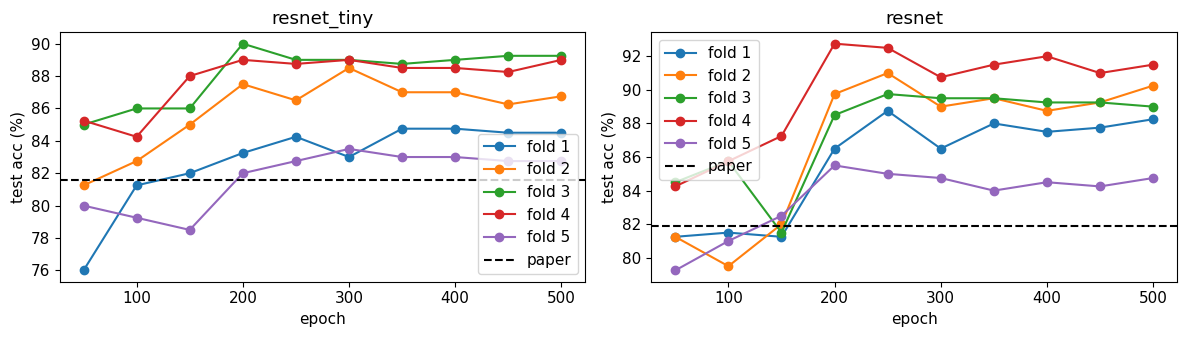

In [ ]:
try:   # the YOLO repos' utils may switch matplotlib to the non-interactive Agg backend
    from IPython import get_ipython
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass

def summarize():
    rows, fold_rows, curves = [], [], {}
    for name in C.models:
        rs = [json.loads(p.read_text()) for p in sorted(RESULTS_DIR.glob(f"{name}_fold*.json"))]
        if not rs:
            continue
        rows.append(dict(model=name, folds_done=len(rs),
                         mean_acc=np.mean([r["final_acc"] for r in rs]), std=np.std([r["final_acc"] for r in rs]),
                         mean_macro_f1=np.mean([r["final_macro_f1"] for r in rs]),
                         mean_weighted_f1=np.mean([r["final_weighted_f1"] for r in rs]),
                         paper_acc=SPECS[name]["paper_acc"], hours=sum(r["seconds"] for r in rs) / 3600))
        fold_rows += [dict(model=name, fold=r["fold"], acc=r["final_acc"], macro_f1=r["final_macro_f1"],
                           weighted_f1=r["final_weighted_f1"], seconds=r["seconds"]) for r in rs]
        curves[name] = rs

    if not curves:
        print(f"[!] Tidak ada hasil di {RESULTS_DIR}. Jalankan sel 'Full run' dulu.")
        return

    summary = pd.DataFrame(rows)
    print(summary.to_string(index=False))
    # ---- simpan tabel ke folder project ----
    durable_write(OUT_DIR / "summary_results.csv", summary.to_csv(index=False))
    durable_write(OUT_DIR / "per_fold_results.csv", pd.DataFrame(fold_rows).to_csv(index=False))

    fig, ax = plt.subplots(1, len(curves), figsize=(6 * max(1, len(curves)), 3.5), squeeze=False)
    for a, (name, rs) in zip(ax[0], curves.items()):
        for r in rs:
            h = [(e["epoch"], e["test_acc"]) for e in r["history"] if "test_acc" in e]
            a.plot(*zip(*h), marker="o", label=f"fold {r['fold']}")
        a.axhline(SPECS[name]["paper_acc"], ls="--", c="k", label="paper")
        a.set_title(name); a.set_xlabel("epoch"); a.set_ylabel("test acc (%)"); a.legend()
    plt.tight_layout()
    # ---- simpan gambar SEBELUM plt.show() ----
    fig_path = FIG_DIR / "accuracy_curves.png"
    fig.savefig(fig_path, dpi=150, bbox_inches="tight")
    print("saved ->", OUT_DIR / "summary_results.csv")
    print("saved ->", OUT_DIR / "per_fold_results.csv")
    print("saved ->", fig_path)
    plt.show()

summarize()

In [ ]:
import shutil
zip_path = shutil.make_archive(str(PROJECT_DIR / "esc50_outputs"), "zip", root_dir=OUT_DIR)
print("zip ->", zip_path, f"[{Path(zip_path).stat().st_size/2**20:.1f} MB]")

zip -> /kaggle/working/esc50_outputs.zip [546.2 MB]
